# Quantitative Research -- Part 1: Descriptive Statistics (revision)

*Revision material: Parts 1 and 2 revise the descriptive statistics that Parts 3–5 build on.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ChrisW09/Quantitative-Research-Methods/blob/main/Part_1_Descriptive_Statistics/Part_1_Descriptive_Statistics.ipynb)

This notebook is the companion of the slide deck *Part 1: Descriptive Statistics*: its
sections follow the slides, and the code cells reproduce the Python commands and numbers
shown there. Run the cells from top to bottom. For the exercises, try the *Your turn*
cell first and only then look at the solution cell below it.

## Contents

- **1 Fundamentals**
    - 1.1 Basic Concepts
    - 1.2 Levels of Measurement
    - 1.3 Exercise
- **2 Descriptive Statistics**
    - 2.1 Frequencies
    - 2.2 Exercises
    - 2.3 Measures of Central Tendency
    - 2.4 Exercises
    - 2.5 Measures of Dispersion
    - 2.6 Exercises
    - 2.7 Exam-Style Exercise
- **3 Summary** -- key Python commands

**Setup:** the packages used in this part (all included in Anaconda and Google Colab).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

pd.set_option("display.precision", 4)

## 1 Fundamentals

### 1.1 Basic Concepts

Slides: *Basic Concepts*, *Basic Concepts: Variable and Observed Values*, *Basic Concepts -- Summary*

| Term | Symbol | Running example of this part |
|---|---|---|
| Statistical unit | $\omega$ | a player of a soccer team ($n = 11$ players) |
| Variable | $X$ | shoe size |
| Value | $x$ | 37, 38, 39, ... |
| Observation | $x_i$ | shoe size of player $i$, e.g. $x_1 = 40$ |

**In words:** the statistical units are what we observe, the variable is what we measure
on them, and the observations $x_1, \ldots, x_n$ are the measured values.

In [2]:
# Running example: shoe sizes x_1, ..., x_n of the 11 players of a soccer team
data = pd.Series([40, 39, 38, 41, 46, 39, 39, 38, 37, 40, 39])
print(len(data))      # n = 11
print(data[0])        # x_1 = 40  (Python counts positions from 0)

11
40


### 1.2 Levels of Measurement

Slides: *Levels of Measurement (1)*, *(2)*

| Level | Explanation | Meaningful operations | Example |
|---|---|---|---|
| Nominal | category only, no ordering | $=$, $\neq$ | colour, payment method |
| Ordinal | ranking possible, differences not meaningful | additionally $<$, $>$ | grades, clothing sizes |
| Metric | ranking possible, differences meaningful | additionally $+$, $-$ | euros, temperatures |

The metric level splits into the **interval scale** (no natural zero, e.g. °C) and the
**ratio scale** (natural zero, ratios meaningful, e.g. euros, counts).

**In words:** each level allows everything the level above it allows -- and one thing more.

Slide: *Levels of Measurement with Python* -- pandas stores nominal data as `category`,
ordinal data as an *ordered* `category`, and metric data as numbers.

In [3]:
import pandas as pd
# Nominal: categories without an order -> data type "category"
colour = pd.Series(["black", "white", "blue", "black"], dtype="category")
print((colour == "black").tolist())    # [True, False, False, True]   (=, != only)
# Ordinal: categories WITH an order (clothing sizes S < M < L < XL)
size = pd.Series(pd.Categorical(["M", "S", "XL", "M"],
                 categories=["S", "M", "L", "XL"], ordered=True))
print(size.max(), (size > "S").sum())  # XL 3                         (additionally <, >)
# Metric: numbers -> differences (and means) are meaningful
price = pd.Series([19.90, 24.90, 29.90, 19.90])   # euros
print(round(price.max() - price.min(), 2), round(price.mean(), 2))   # 10.0 23.65

[True, False, False, True]
XL 3
10.0 23.65


### 1.3 Exercise

#### Exercise -- Levels of Measurement

An online retailer records the following variables for every order (statistical unit):

| | Variable | | Variable |
|---|---|---|---|
| 1 | Postcode of the delivery address | 5 | Order value in euros |
| 2 | Payment method (invoice, PayPal, card) | 6 | Delivery time in days |
| 3 | Customer rating (1 to 5 stars) | 7 | Customer status (new / regular / premium) |
| 4 | Number of items ordered | 8 | Order date (calendar date) |


a) Assign each variable its level of measurement (nominal, ordinal, metric); give a brief reason.

b) For the metric variables: interval or ratio scale? (Is "twice as much" meaningful?)

In [4]:
# Your turn: replace "?" by nominal / ordinal / metric (interval) / metric (ratio)
variables = ["Postcode", "Payment method", "Customer rating", "Number of items",
             "Order value", "Delivery time", "Customer status", "Order date"]
levels = {v: "?" for v in variables}
levels

{'Postcode': '?',
 'Payment method': '?',
 'Customer rating': '?',
 'Number of items': '?',
 'Order value': '?',
 'Delivery time': '?',
 'Customer status': '?',
 'Order date': '?'}

**Solution**

In [5]:
# Rule: nominal -> categories; ordinal -> + ranking; metric -> + differences;
#       ratio scale -> + natural zero
solution = pd.DataFrame({
    "Variable": ["Postcode", "Payment method", "Customer rating", "Number of items",
                 "Order value", "Delivery time", "Customer status", "Order date"],
    "Level": ["nominal", "nominal", "ordinal", "metric (ratio)",
              "metric (ratio)", "metric (ratio)", "ordinal", "metric (interval)"],
    "Reason": ["the number is only a code, no ranking",
               "categories without an order",
               "ranking, but distances between stars not comparable",
               "differences and ratios meaningful",
               "natural zero (0 euros); 'twice as expensive' meaningful",
               "differences and ratios meaningful",
               "new < regular < premium, but no measurable distance",
               "distances in days meaningful, but no natural zero"]},
    index=range(1, 9))
solution

,Variable,Level,Reason
1,Postcode,nominal,"the number is only a code, no ranking"
2,Payment method,nominal,categories without an order
3,Customer rating,ordinal,"ranking, but distances between stars not compa..."
4,Number of items,metric (ratio),differences and ratios meaningful
5,Order value,metric (ratio),natural zero (0 euros); 'twice as expensive' m...
6,Delivery time,metric (ratio),differences and ratios meaningful
7,Customer status,ordinal,"new < regular < premium, but no measurable dis..."
8,Order date,metric (interval),"distances in days meaningful, but no natural zero"


In [6]:
# Numbers used as codes: store postcodes as categories -- counting is meaningful,
# an "average postcode" is not
postcode = pd.Series(["10115", "80331", "20095", "10115"], dtype="category")
print(postcode.value_counts().to_dict())   # {'10115': 2, '20095': 1, '80331': 1}

{'10115': 2, '20095': 1, '80331': 1}


## 2 Descriptive Statistics

### 2.1 Frequencies

Slide: *Frequencies* -- for each distinct value $x_j$ ($j = 1, \ldots, k$), sorted in ascending order:

- absolute frequency $h_j = \#\{i \mid x_i = x_j\}$
- relative frequency $f_j = h_j / n$
- cumulative absolute frequency $H_j = \sum_{l \le j} h_l$
- cumulative relative frequency $F(x) = \sum_{x_j \le x} f_j$

**In words:** count, divide by $n$, add up from the left. Checks: $\sum_j h_j = n$ and $\sum_j f_j = 1$.

Slides: *The Data -- an Example (2)*, *Frequency Table* -- the shoe sizes
40, 39, 38, 41, 46, 39, 39, 38, 37, 40, 39.

In [7]:
n = len(data)
abs_freq = data.value_counts().sort_index()                # h_j
rel_freq = data.value_counts(normalize=True).sort_index()  # f_j
table = pd.DataFrame({
    "Absolute frequency": abs_freq,
    "Relative frequency (decimal)": rel_freq.round(4),
    "Relative frequency in %": (100 * rel_freq).round(1),
    "Relative frequency (fraction)": [f"{h}/{n}" for h in abs_freq],
    "Cumulative absolute frequency": abs_freq.cumsum(),
    "Cumulative rel. freq. (decimal)": rel_freq.cumsum().round(4),
    "Cumulative rel. freq. (fraction)": [f"{h}/{n}" for h in abs_freq.cumsum()],
})
table.T            # one column per shoe size, as on the slide

,37,38,39,40,41,46
Absolute frequency,1,2,4,2,1,1
Relative frequency (decimal),0.0909,0.1818,0.3636,0.1818,0.0909,0.0909
Relative frequency in %,9.1,18.2,36.4,18.2,9.1,9.1
Relative frequency (fraction),1/11,2/11,4/11,2/11,1/11,1/11
Cumulative absolute frequency,1,3,7,9,10,11
Cumulative rel. freq. (decimal),0.0909,0.2727,0.6364,0.8182,0.9091,1.0
Cumulative rel. freq. (fraction),1/11,3/11,7/11,9/11,10/11,11/11


Slide: *Comparing Relative Frequencies: Percent vs. Percentage Points* -- the share of
5-star ratings rises from 40 % to 50 %:
absolute difference $50\,\% - 40\,\% = 10$ **percentage points**,
relative change $(50\,\% - 40\,\%)/40\,\% = 0.25 = 25\,\%$.

**In words:** percentage points are the absolute difference of two shares, percent the
change relative to the starting level.

In [8]:
print(50 - 40, round((50 - 40) / 40, 4))     # 10 0.25

10 0.25


#### Exercise -- Frequencies of a Nominal Variable

The online retailer records the payment method of $n = 10$ orders (I = invoice, P = PayPal, C = card):

P, C, I, P, P, C, P, I, C, P


a) Determine the absolute frequencies $h_j$ and the relative frequencies $f_j$ (fraction, decimal, %).

b) Which share of the orders is **not** paid by invoice? How many orders is that?

c) Last month, 25 % of the orders were paid by invoice. By how many percentage points and by
how many percent has this share changed?

d) Does a cumulative relative frequency $F(x)$ make sense here? Give a reason.

In [9]:
# Your turn: payment methods of the n = 10 orders
pay = pd.Series(["P", "C", "I", "P", "P", "C", "P", "I", "C", "P"])

**Solution**

In [10]:
# a) h_j and f_j in the order invoice, PayPal, card
h_pay = pay.value_counts()[["I", "P", "C"]]
f_pay = h_pay / len(pay)
print(h_pay.tolist(), f_pay.tolist())                  # [2, 5, 3] [0.2, 0.5, 0.3]
# b) not by invoice: 1 - f_invoice, and the number of orders
print(round(1 - f_pay["I"], 2), (pay != "I").sum())    # 0.8 8
# c) invoice share 25 % -> 20 %: percentage points and percent
print(round(100 * (f_pay["I"] - 0.25), 2),
      round((f_pay["I"] - 0.25) / 0.25, 4))            # -5.0 -0.2
# d) "cumulative up to PayPal" depends on the arbitrary column order -> not meaningful
print(round(f_pay["I"] + f_pay["P"], 2),
      round(f_pay["C"] + f_pay["P"], 2))               # 0.7 0.8

[2, 5, 3] [0.2, 0.5, 0.3]
0.8 8
-5.0 -0.2
0.7 0.8


Slides: *Why Statistics Software?*, *What is Python?*, *Working Environment: Jupyter and VS Code*,
*Installation (Mac & Windows)* -- this notebook runs in Jupyter, VS Code or Google Colab.
Step 3 of the installation, the first test (no error message means you are ready):

In [11]:
import numpy, pandas, scipy, statsmodels, matplotlib
print(numpy.__version__, pandas.__version__)

2.0.2 2.3.3


Slide: *Frequencies with Python* -- `value_counts()` sorts by frequency; `sort_index()`
orders by shoe size (needed for `cumsum()`).

In [12]:
import pandas as pd

# Soccer team - shoe sizes of the 11 players
data = pd.Series([40, 39, 38, 41, 46, 39, 39, 38, 37, 40, 39])

# Frequency table (absolute frequencies), sorted by shoe size
print(data.value_counts().sort_index())
# Relative frequencies
print(data.value_counts(normalize=True).sort_index().round(4))
# Cumulative (relative) frequencies
print(data.value_counts(normalize=True).sort_index().cumsum().round(4))

37    1
38    2
39    4
40    2
41    1
46    1
Name: count, dtype: int64
37    0.0909
38    0.1818
39    0.3636
40    0.1818
41    0.0909
46    0.0909
Name: proportion, dtype: float64
37    0.0909
38    0.2727
39    0.6364
40    0.8182
41    0.9091
46    1.0000
Name: proportion, dtype: float64


Slides: *Column Chart*, *Bar Chart*, *Pie Chart*, *Empirical Distribution Function* and
*Charts with Python*. The empirical distribution function is the step function
$F(x) = \#\{i \mid x_i \le x\} / n$.

**In words:** column and bar charts show the $h_j$ as heights or lengths, the pie chart
shows the shares $f_j$, and $F(x)$ is the share of observations at or below $x$.

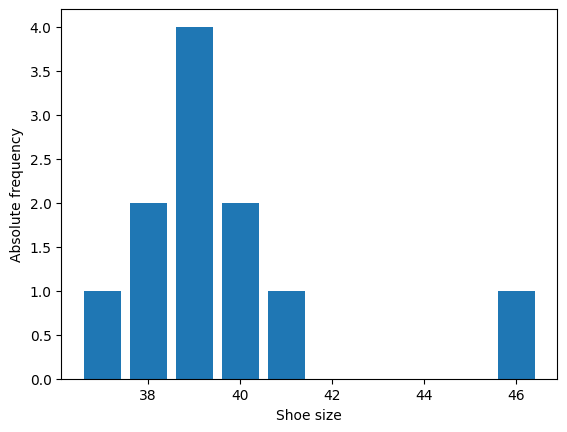

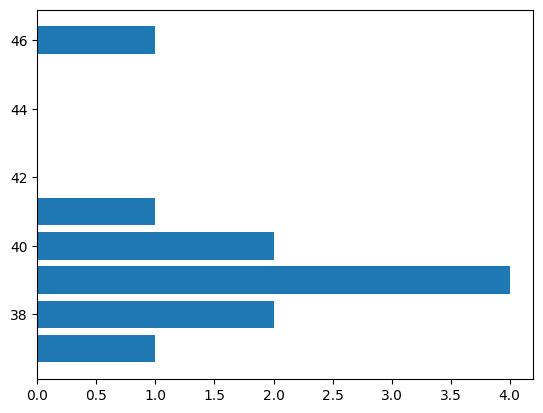

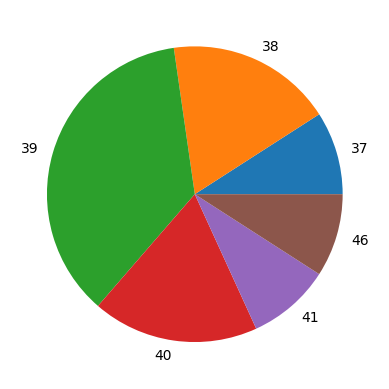

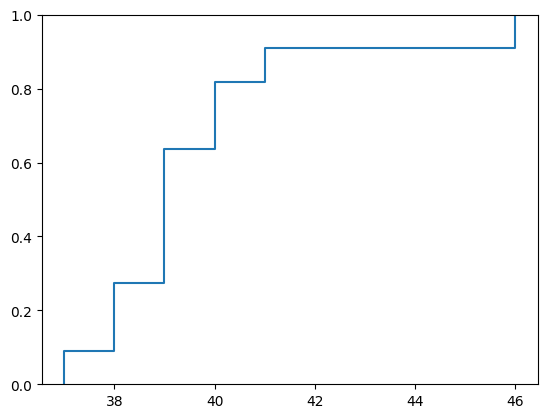

In [13]:
import matplotlib.pyplot as plt
counts = data.value_counts().sort_index()        # h_j: 37:1, 38:2, 39:4, 40:2, 41:1, 46:1

plt.bar(counts.index, counts.values)             # column chart (numeric axis: gap 41-46)
plt.xlabel("Shoe size"); plt.ylabel("Absolute frequency")
plt.show()
plt.barh(counts.index, counts.values)            # bar chart (horizontal bars)
plt.show()
plt.pie(counts.values, labels=counts.index)      # pie chart: slice = share f_j
plt.show()
plt.ecdf(data)                                   # empirical distribution function F(x)
plt.show()

### 2.2 Exercises

#### Exercise -- Frequency Table

A café has received $n = 12$ ratings (1 to 5 stars) on a review platform:

4, 5, 3, 4, 5, 5, 2, 4, 5, 3, 4, 5


a) Set up the frequency table with absolute frequencies $h_j$, relative frequencies $f_j$
(as fraction and decimal) and cumulative relative frequencies $F(x_j)$.

b) What share of the ratings has **at most** 3 stars?

c) What share of the ratings has **at least** 4 stars? How many ratings is that?

d) Read from the table: which rating is the most frequent one?

e) Last year, 30 % of the ratings had 5 stars. By how many percentage points and by how many
percent has this share changed?

In [14]:
# Your turn: the 12 ratings
stars = pd.Series([4, 5, 3, 4, 5, 5, 2, 4, 5, 3, 4, 5])

**Solution**

In [15]:
# a) frequency table: h_j, f_j (fraction and decimal), F(x_j)
h = stars.value_counts().sort_index()
f = stars.value_counts(normalize=True).sort_index()
pd.DataFrame({"h_j": h, "f_j (fraction)": [f"{k}/{len(stars)}" for k in h],
              "f_j": f.round(4), "F(x_j)": f.cumsum().round(4)}).T

,2,3,4,5
h_j,1,2,4,5
f_j (fraction),1/12,2/12,4/12,5/12
f_j,0.0833,0.1667,0.3333,0.4167
F(x_j),0.0833,0.25,0.5833,1.0


In [16]:
# Code as on slide "Solution (2/2) -- Frequency Table"
print(stars.value_counts().sort_index().tolist())     # [1, 2, 4, 5]
F = stars.value_counts(normalize=True).sort_index().cumsum()
print(F.round(4).tolist())                            # [0.0833, 0.25, 0.5833, 1.0]
print((stars <= 3).mean(), (stars >= 4).sum())        # 0.25 9   (b and c)

[1, 2, 4, 5]
[0.0833, 0.25, 0.5833, 1.0]
0.25 9


In [17]:
# c) share "at least 4" = 1 - F(3);  d) most frequent rating
print(1 - (stars <= 3).mean(), stars.mode().tolist())          # 0.75 [5]
# e) share of 5 stars: 41.67 % this year vs. 30 % last year
f5 = (stars == 5).mean()
print(round(100 * f5, 2), round(100 * f5 - 30, 2),
      round(100 * (f5 - 0.30) / 0.30, 1))                      # 41.67 11.67 38.9

0.75 [5]
41.67 11.67 38.9


### 2.3 Measures of Central Tendency

Slide: *Refresher: Summation and Product Signs* --
$\sum_{i=1}^{n} x_i = x_1 + \cdots + x_n$ and $\prod_{i=1}^{n} x_i = x_1 \cdot \ldots \cdot x_n$.

**In words:** first square, then add -- $\sum x_i^2 \neq (\sum x_i)^2$.

In [18]:
print(data[:3].sum(), np.prod(data[:3]))     # 117 59280   (first three players: 40, 39, 38)
print(1**2 + 2**2, (1 + 2)**2)               # 5 9         (sum of squares vs. square of the sum)

117 59280
5 9


Slide: *Means (1): Arithmetic Mean and Trimmed Mean* --
$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$; the trimmed mean removes the $\lfloor \alpha n \rfloor$
smallest and largest values and averages the rest.

**In words:** the mean is the value every unit would have if the total were shared out equally.

In [19]:
print(round(data.mean(), 4))                       # 39.6364
k = math.floor(0.10 * len(data))                   # floor(0.1 * 11) = 1 value per end
xs = np.sort(data.to_numpy())
print(k, round(xs[k:len(xs) - k].mean(), 4))       # 1 39.2222   (= 353 / 9)

39.6364
1 39.2222


Slide: *Means (2): Geometric Mean -- Averaging Growth Rates* --
$\bar{x}_{\text{geo}} = \left(\prod_{i=1}^{n} x_i\right)^{1/n}$; average growth rate
$= \bar{x}_{\text{geo}}$ of the growth factors $1 + r_i$, minus 1.

**In words:** growth factors multiply, so their typical value is the geometric mean.

In [20]:
g = np.array([1.20, 0.90])                         # growth factors for +20 % and -10 %
print(round(np.prod(g), 4), round(stats.gmean(g), 4))   # 1.08 1.0392  -> +3.92 % per year
print(round(stats.gmean(g) ** 2, 4), round(1.05 ** 2, 4))   # 1.08 1.1025  (check; 5 % would be wrong)

1.08 1.0392
1.08 1.1025


Slides: *Median*, *Mode*, *Which Measure for Which Level of Measurement?* --
median $\tilde{x} = x_{(\lceil n/2 \rceil)}$ (course definition), mode = most frequent value.
Mode: all levels; median and quantiles: from ordinal; arithmetic mean: metric only.

**In words:** the median is the value in the middle of the sorted data; at least half of
the values lie at or below it.

In [21]:
print(np.quantile(data, 0.5, method="inverted_cdf"))   # 39   (course median x_(ceil(n/2)))
print(data.mode().tolist())                            # [39]

39
[39]


Slide: *Measures of Central Tendency -- Example*

In [22]:
measures = {"Sum": data.sum(), "Arithmetic mean": data.mean(),
            "Geometric mean": stats.gmean(data),
            "Trimmed mean (10 % per end)": stats.trim_mean(data, 0.10),
            "Median": np.quantile(data, 0.5, method="inverted_cdf"),
            "Mode": data.mode()[0]}
for name, value in measures.items():
    print(f"{name:28s} {round(float(value), 4):g}")
# 436 | 39.6364 | 39.5755 | 39.2222 | 39 | 39

Sum                          436
Arithmetic mean              39.6364
Geometric mean               39.5755
Trimmed mean (10 % per end)  39.2222
Median                       39
Mode                         39


#### Exercise -- Mean, Median and Mode

An electronics shop records the number of laptops sold on $n = 9$ days:

4, 7, 3, 5, 4, 6, 4, 2, 10


a) Compute the arithmetic mean, the median, the mode and the trimmed mean with $\alpha = 20\,\%$.

b) On day 9 the shop actually sold 19 laptops (a large company order), not 10. Which of the four
measures change, and to which value?

c) $n = 7$ customers rate the service: good, very good, fair, good, poor, good, very good.
Which of the measures may be used for this variable? Determine them.

In [23]:
# Your turn: laptops sold and service ratings
laptops = np.array([4, 7, 3, 5, 4, 6, 4, 2, 10])
ratings = ["good", "very good", "fair", "good", "poor", "good", "very good"]

**Solution**

In [24]:
# a) sorted data, mean, median x_(ceil(n/2)), mode, trimmed mean (alpha = 20 %)
print(np.sort(laptops), laptops.sum())                         # [ 2  3  4  4  4  5  6  7 10] 45
print(laptops.mean(), np.quantile(laptops, 0.5, method="inverted_cdf"),
      pd.Series(laptops).mode().tolist())                      # 5.0 4 [4]
print(math.floor(0.2 * 9), round(stats.trim_mean(laptops, 0.20), 4))   # 1 4.7143  (= 33 / 7)

[ 2  3  4  4  4  5  6  7 10] 45
5.0 4 [4]
1 4.7143


In [25]:
# b) 19 instead of 10: only the mean changes (5 -> 6)
laptops_b = np.array([4, 7, 3, 5, 4, 6, 4, 2, 19])
print(laptops_b.sum(), laptops_b.mean(),
      np.quantile(laptops_b, 0.5, method="inverted_cdf"),
      pd.Series(laptops_b).mode().tolist(),
      round(stats.trim_mean(laptops_b, 0.20), 4))              # 54 6.0 4 [4] 4.7143

54 6.0 4 [4] 4.7143


In [26]:
# c) ordinal variable: median and mode, but no mean
r = pd.Series(pd.Categorical(ratings, categories=["poor", "fair", "good", "very good"],
                             ordered=True))
r_sorted = r.sort_values()
print(r_sorted.tolist())     # ['poor', 'fair', 'good', 'good', 'good', 'very good', 'very good']
print(r_sorted.iloc[math.ceil(7 / 2) - 1], r.mode().tolist())   # good ['good']

['poor', 'fair', 'good', 'good', 'good', 'very good', 'very good']
good ['good']


Slide: *Arithmetic Mean from a Frequency Table* --
$\bar{x} = \frac{1}{n}\sum_{j=1}^{k} h_j \cdot x_j = \sum_{j=1}^{k} f_j \cdot x_j$.

**In words:** a weighted mean -- every value counts as often as it occurs.

In [27]:
xj = np.array([37, 38, 39, 40, 41, 46])
hj = np.array([1, 2, 4, 2, 1, 1])
print((hj * xj).tolist(), (hj * xj).sum())       # [37, 76, 156, 80, 41, 46] 436
print(round((hj * xj).sum() / hj.sum(), 4))      # 39.6364

[37, 76, 156, 80, 41, 46] 436
39.6364


Slides: *Measures of Central Tendency with Python (1)* and *(2)* -- the slide commands;
`round(..., 4)` only shortens the printed numbers to the 4 decimals of the slides.

In [28]:
import numpy as np
from scipy import stats
# Sum
print(data.sum())                            # 436
# Arithmetic mean
print(round(data.mean(), 4))                 # 39.6364
# Geometric mean
# Step 1: Calculate the product of all values
product = np.prod(data)
# Step 2: Determine the number of observations
n = len(data)
# Step 3: Take the n-th root
gmean = product ** (1 / n)
print(round(gmean, 4))                       # 39.5755
print(round(stats.gmean(data), 4))           # same result in one step

436
39.6364
39.5755
39.5755


In [29]:
# Trimmed mean: 10% of the values are removed at EACH end
print(round(stats.trim_mean(data, 0.10), 4))  # 39.2222

# Median
print(np.median(data))                        # 39.0

# Mode (all most frequent values, as a list)
print(data.mode().tolist())                   # [39]

# Mean from a frequency table: weighted mean
print(round(np.average([37, 38, 39, 40, 41, 46], weights=[1, 2, 4, 2, 1, 1]), 4))  # 39.6364

# Note: for even n, np.median() averages the two middle values; the course
# definition x_(ceil(n/2)) is obtained with method="inverted_cdf"
even = [34, 37, 40, 41]
print(np.median(even), np.quantile(even, 0.5, method="inverted_cdf"))   # 38.5 37

39.2222
39.0
[39]
39.6364
38.5 37


Slides: *Quantiles*, *Quantiles -- Computation*, *Quantiles -- Computation Example*,
*Quantiles -- Worked Example* --
$x_p = x_{(\lceil n \cdot p \rceil)} = \min\{x \mid F(x) \ge p\}$.

**In words:** sort the data, compute $n \cdot p$, round up (an integer stays as it is) and
take the value at this position -- at least $p \cdot 100\,\%$ of the values lie at or below it.

In [30]:
xs = np.sort(data.to_numpy())
print(xs.tolist())                         # [37, 38, 38, 39, 39, 39, 39, 40, 40, 41, 46]
rows = []
for name, p in [("1st quartile", 0.25), ("2nd quartile", 0.50), ("3rd quartile", 0.75),
                ("17%-quantile", 0.17), ("80%-quantile", 0.80), ("5%-quantile", 0.05)]:
    pos = math.ceil(round(len(xs) * p, 10))      # round() avoids 8.800000000000001
    rows.append([name, p, round(len(xs) * p, 2), pos, xs[pos - 1]])
pd.DataFrame(rows, columns=["Quantile", "p", "n * p", "Position", "Value"])

[37, 38, 38, 39, 39, 39, 39, 40, 40, 41, 46]


,Quantile,p,n * p,Position,Value
0,1st quartile,0.25,2.75,3,38
1,2nd quartile,0.50,5.50,6,39
2,3rd quartile,0.75,8.25,9,40
3,17%-quantile,0.17,1.87,2,38
4,80%-quantile,0.80,8.80,9,40
5,5%-quantile,0.05,0.55,1,37


#### Exercise -- Quantiles of Hotline Waiting Times

A customer hotline measures the waiting time (in minutes, rounded) of $n = 12$ calls:

3, 1, 5, 2, 6, 4, 2, 8, 3, 4, 2, 5


a) Sort the data.

b) Determine the 10 %-quantile, $Q_1$, the median, $Q_3$ and the 90 %-quantile.

c) The hotline wants to promise: "At least 90 % of our callers wait at most $x$ minutes."
What is the smallest $x$ supported by the data?

d) A colleague reports a median of 3.5 minutes. How did they obtain this value, and what is
the median according to the course definition?

In [31]:
# Your turn: waiting times in minutes
wait = np.array([3, 1, 5, 2, 6, 4, 2, 8, 3, 4, 2, 5])

**Solution**

In [32]:
# a) sorted data
print(np.sort(wait))                       # [1 2 2 2 3 3 4 4 5 5 6 8]
# b) position ceil(n * p), value x_(position)
for name, p in [("10%-quantile", 0.10), ("Q1", 0.25), ("Median", 0.50),
                ("Q3", 0.75), ("90%-quantile", 0.90)]:
    pos = math.ceil(round(len(wait) * p, 10))
    print(f"{name:12s} n*p = {len(wait) * p:4.1f}  position {pos:2d}  value "
          f"{np.quantile(wait, p, method='inverted_cdf')}")
# values: 2, 2, 3, 5, 6

[1 2 2 2 3 3 4 4 5 5 6 8]
10%-quantile n*p =  1.2  position  2  value 2
Q1           n*p =  3.0  position  3  value 2
Median       n*p =  6.0  position  6  value 3
Q3           n*p =  9.0  position  9  value 5
90%-quantile n*p = 10.8  position 11  value 6


In [33]:
# c) 90 %-quantile = 6 minutes; check with F(6) and F(5)
print(round((wait <= 6).mean(), 4), round((wait <= 5).mean(), 4))   # 0.9167 0.8333
# d) the colleague averaged x_(6) and x_(7); the course median is x_(6)
print(np.median(wait), np.quantile(wait, 0.5, method="inverted_cdf"))   # 3.5 3

0.9167 0.8333
3.5 3


Slide: *Quantiles with Python* -- always pass `method="inverted_cdf"` to get the course
definition $x_{(\lceil n \cdot p \rceil)}$.

In [34]:
# Course definition x_(ceil(n*p)): method="inverted_cdf"
# All standard quantiles at once (0, 25, 50, 75, 100 %)
p = [0, 0.25, 0.50, 0.75, 1]
print(np.quantile(data, p, method="inverted_cdf"))     # [37 38 39 40 46]

# 1st quartile (25%-quantile)
print(np.quantile(data, 0.25, method="inverted_cdf"))  # 38

# 80%-quantile
print(np.quantile(data, 0.80, method="inverted_cdf"))  # 40

# Pitfall: the default method interpolates
print(np.quantile(data, 0.25), data.quantile(0.25))    # 38.5 38.5

[37 38 39 40 46]
38
40
38.5 38.5


### 2.4 Exercises

#### Exercise -- Measures of Central Tendency and Quantiles

Annual salaries (in thousand euros) of the $n = 10$ employees of a department, including the
head of department:

34, 42, 28, 120, 36, 31, 45, 34, 50, 39


a) Sort the data and compute the arithmetic mean, the median and the mode.

b) Compute the trimmed mean (remove 10 % of the values at each end).

c) Determine $Q_1$, $Q_3$ and the 20 %- and 90 %-quantiles.

d) Which measure best describes the "typical" salary in the department? Give reasons.

In [35]:
# Your turn: salaries in thousand euros
salary = np.array([34, 42, 28, 120, 36, 31, 45, 34, 50, 39])

**Solution**

In [36]:
# Python check as on slide "Solution (4/4)"; course quantiles need method="inverted_cdf"
print(np.sort(salary))
print(salary.mean(), stats.trim_mean(salary, 0.10))
print(pd.Series(salary).mode().tolist())
print(np.quantile(salary, 0.5, method="inverted_cdf"), np.median(salary))
print(np.quantile(salary, [0.2, 0.25, 0.75, 0.9], method="inverted_cdf"))

[ 28  31  34  34  36  39  42  45  50 120]
45.9 38.875
[34]
36 37.5
[31 34 45 50]


In [37]:
# Intermediate values of the solution slides
print(salary.sum(), (salary < salary.mean()).sum())       # 459 8  (8 of 10 earn less than the mean)
print(np.sort(salary)[1:-1].sum())                        # 311  -> trimmed mean 311 / 8 = 38.875
for p in [0.20, 0.25, 0.75, 0.90]:
    print(p, round(10 * p, 1), math.ceil(round(10 * p, 10)))   # n*p and position: 2, 3, 8, 9

459 8
311
0.2 2.0 2
0.25 2.5 3
0.75 7.5 8
0.9 9.0 9


d) The head of department (120) is an outlier and pulls the mean up to 45.9; the **median (36)** and the trimmed mean (38.875) describe the typical salary better.

#### Exercise -- Geometric Mean

The revenue of a start-up was exactly 200 thousand euros in year 0. In the following three years
it changed by +10 %, -5 %, +20 %.


a) What is the revenue after three years?

b) Compute the arithmetic mean of the three growth rates. Which revenue after three years would
you obtain if revenue had grown by this mean every year?

c) Compute the average annual growth rate via the geometric mean of the growth factors and check
the result.

d) Why does the arithmetic mean in b) give a wrong result?

In [38]:
# Your turn: growth factors 1 + r_i
factors = np.array([1.10, 0.95, 1.20])

**Solution**

In [39]:
# Code as on slide "Solution (2/2)" (rounded to 4 decimals)
print(round(200 * np.prod(factors), 1))       # 250.8
print(round(factors.mean() - 1, 4))           # 0.0833  (arithmetic: wrong)
print(round(stats.gmean(factors) - 1, 4))     # 0.0784  (geometric: correct)

250.8
0.0833
0.0784


In [40]:
# b) revenue with the arithmetic mean rate; c) check with the geometric mean
r_bar = factors.mean() - 1
print(round((1 + r_bar) ** 3, 4), round(200 * (1 + r_bar) ** 3, 1))   # 1.2714 254.3  (too high)
x_geo = stats.gmean(factors)
print(round(x_geo, 4), round(200 * x_geo ** 3, 1))                    # 1.0784 250.8  (check)

1.2714 254.3
1.0784 250.8


### 2.5 Measures of Dispersion

Slides: *Measures of Dispersion -- Why?*, *Visualisation* -- shoe sizes of two women's rowing
fours: same mean and median, but different dispersion.

In [41]:
four_a = np.array([34, 37, 40, 41])
four_b = np.array([36, 37, 39, 40])
for x in (four_a, four_b):
    print(x.mean(), np.quantile(x, 0.5, method="inverted_cdf"))   # 38.0 37 (both fours)

38.0 37
38.0 37


Slide: *Range and Interquartile Range* -- $R = x_{(n)} - x_{(1)}$, $\text{IQR} = Q_3 - Q_1$.

**In words:** $R$ is the width of the whole data set, the IQR the width of its middle 50 %.

In [42]:
q1, q3 = np.quantile(data, [0.25, 0.75], method="inverted_cdf")
print(np.ptp(data), q3 - q1)                          # 9 2   (soccer team)
for x in (four_a, four_b):
    q1, q3 = np.quantile(x, [0.25, 0.75], method="inverted_cdf")
    print(np.ptp(x), q1, q3, q3 - q1)                 # A: 7 34 40 6 | B: 4 36 39 3

9 2
7 34 40 6
4 36 39 3


Slides: *Sample Variance*, *Sample Variance -- Worked Example* --
$s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar{x})^2$.

**In words:** roughly the average squared distance of the values from their mean.

In [43]:
for x in (four_a, four_b):
    d = x - x.mean()
    print(d.tolist(), d.sum(), (d ** 2).sum(), round((d ** 2).sum() / (len(x) - 1), 4))
# A: deviations -4, -1, 2, 3 -> sum of squares 30 -> s^2 = 10
# B: deviations -2, -1, 1, 2 -> sum of squares 10 -> s^2 = 3.3333

[-4.0, -1.0, 2.0, 3.0] 0.0 30.0 10.0
[-2.0, -1.0, 1.0, 2.0] 0.0 10.0 3.3333


Slides: *Standard Deviation*, *Standard Deviation -- Worked Example* -- $s = +\sqrt{s^2}$.

**In words:** the standard deviation measures the dispersion in the unit of the data.

In [44]:
print(round(math.sqrt(10), 4), round(math.sqrt(10 / 3), 4))   # 3.1623 1.8257

3.1623 1.8257


#### Exercise -- Variance and Standard Deviation

The online retailer compares two parcel services. Delivery times (in days) of $n = 5$ orders each:

| Order $i$ | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Parcel service A | 2 | 5 | 1 | 3 | 4 |
| Parcel service B | 4 | 3 | 5 | 4 | 4 |


a) Compute the mean $\bar{x}$ and the range $R$ for both services.

b) Compute the sample variance $s^2$ and the standard deviation $s$ (with units).

c) Which service delivers faster on average, which more reliably? Give reasons.

In [45]:
# Your turn: delivery times in days
service_a = np.array([2, 5, 1, 3, 4])
service_b = np.array([4, 3, 5, 4, 4])

**Solution**

In [46]:
for name, x in [("A", service_a), ("B", service_b)]:
    d = x - x.mean()                                       # deviations from the mean
    print(name, x.mean(), np.ptp(x), d.tolist(), (d ** 2).sum(),
          np.var(x, ddof=1), round(np.std(x, ddof=1), 4))
# A: mean 3 days, R = 4, sum of squares 10, s^2 = 2.5 days^2, s = 1.5811 days
# B: mean 4 days, R = 2, sum of squares  2, s^2 = 0.5 days^2, s = 0.7071 days

A 3.0 4 [-1.0, 2.0, -2.0, 0.0, 1.0] 10.0 2.5 1.5811
B 4.0 2 [0.0, -1.0, 1.0, 0.0, 0.0] 2.0 0.5 0.7071


c) A is faster on average (3 vs. 4 days), B is more reliable ($s_B = 0.71$ vs. $s_A = 1.58$ days).

Slide: *Variance from a Frequency Table* --
$s^2 = \frac{1}{n-1}\sum_{j=1}^{k} h_j \cdot (x_j - \bar{x})^2$.

**In words:** as for the mean, every squared deviation enters the sum $h_j$ times.

In [47]:
xbar = data.mean()
contrib = hj * (xj - xbar) ** 2
print((xj - xbar).round(4).tolist())          # [-2.6364, -1.6364, -0.6364, 0.3636, 1.3636, 6.3636]
print(contrib.round(4).tolist(), round(contrib.sum(), 4))   # ... 40.4959] 56.5455
s2 = contrib.sum() / (len(data) - 1)
print(round(s2, 4), round(math.sqrt(s2), 4))  # 5.6545 2.3779
print(round(contrib[-1] / contrib.sum() * 100, 1))   # 71.6 (% of the sum of squares from size 46)

[-2.6364, -1.6364, -0.6364, 0.3636, 1.3636, 6.3636]
[6.9504, 5.3554, 1.6198, 0.2645, 1.8595, 40.4959] 56.5455
5.6545 2.3779
71.6


Slides: *Coefficient of Variation*, *Coefficient of Variation -- Worked Example* --
$v = s / \bar{x}$ for positive data.

**In words:** the standard deviation as a share of the mean -- independent of the scale.

In [48]:
v_a = np.std(four_a, ddof=1) / np.mean(four_a)
v_b = np.std(four_b, ddof=1) / np.mean(four_b)
print(f"{v_a:.4f} {v_b:.4f}")                  # 0.0832 0.0480
print(np.mean([-10, -5, 5, 11]))              # 0.25 (mixed signs: v would be meaningless)

0.0832 0.0480
0.25


Slides: *Normalised Coefficient of Variation*, *Worked Example* --
$v^* = v / \sqrt{n}$ with $0 \le v^* \le 1$.

**In words:** $v$ rescaled to $[0, 1]$; not suitable for comparing samples of different size.

In [49]:
print(f"{v_a / np.sqrt(4):.4f} {v_b / np.sqrt(4):.4f}")         # 0.0416 0.0240
extreme = np.array([0, 0, 0, 5])              # extreme case: all values but one are 0
v_ext = np.std(extreme, ddof=1) / np.mean(extreme)
print(round(v_ext, 4), round(v_ext / np.sqrt(4), 4))             # 2.0 1.0  (v = sqrt(n), v* = 1)

0.0416 0.0240
2.0 1.0


Slide: *Overview of Measures of Dispersion*

In [50]:
def overview(x):
    q1, q3 = np.quantile(x, [0.25, 0.75], method="inverted_cdf")
    s = np.std(x, ddof=1)
    return {"Mean": np.mean(x), "Median": np.quantile(x, 0.5, method="inverted_cdf"),
            "Range": np.ptp(x), "Interquartile range": q3 - q1,
            "Sample variance": np.var(x, ddof=1), "Standard deviation": s,
            "Coefficient of variation": s / np.mean(x),
            "Normalised coefficient of variation": s / np.mean(x) / np.sqrt(len(x))}

pd.DataFrame({"Four A": overview(four_a), "Four B": overview(four_b)}).round(4)

,Four A,Four B
Mean,38.0000,38.0000
Median,37.0000,37.0000
Range,7.0000,4.0000
Interquartile range,6.0000,3.0000
Sample variance,10.0000,3.3333
Standard deviation,3.1623,1.8257
Coefficient of variation,0.0832,0.0480
Normalised coefficient of variation,0.0416,0.0240


Slide: *Measures of Dispersion with Python* -- NumPy divides by $n$ by default:
always pass `ddof=1` (pandas' `.var()` and `.std()` already use `ddof=1`).

In [51]:
four_a = np.array([34, 37, 40, 41])
# Range and interquartile range (course quantiles)
print(np.ptp(four_a))                                   # 7
q1, q3 = np.quantile(four_a, [0.25, 0.75], method="inverted_cdf")
print(q3 - q1)                                          # 6
# Sample variance (ddof=1: divide by n-1) and standard deviation
print(np.var(four_a, ddof=1), round(np.std(four_a, ddof=1), 4))   # 10.0 3.1623
# Coefficient of variation and normalised coefficient of variation
v = np.std(four_a, ddof=1) / np.mean(four_a)            # 0.0832
vstar = v / np.sqrt(len(four_a))                        # 0.0416
print(round(v, 4), round(vstar, 4))
# Pitfall: default ddof=0 divides by n
print(np.var(four_a), pd.Series(four_a).var())          # 7.5 10.0

7
6
10.0 3.1623
0.0832 0.0416
7.5 10.0


### 2.6 Exercises

#### Exercise -- Which Measure of Dispersion for Which Comparison?

Which measures of dispersion ($s^2$, $s$, $v$, $v^*$) are suitable for comparing

1. the shoe sizes of the rowing four and the rowing eight?
2. the shoe sizes of the women's four and the men's four?
3. the shoe sizes of the women's four and the women's four with coxswain?
4. the shoe sizes of the women's four and the men's eight?

*Hint:* $s^2$ and $s$ depend on the scale; $v$ and $v^*$ do not. The sample size affects
$s^2$, $s$ and $v$ only through the precision of the estimate, but $v^*$ decreases with $n$
($\propto 1/\sqrt{n}$).

In [52]:
# Your turn: replace "?" by "yes" or "no"
answer = pd.DataFrame("?", index=["Sample variance", "Standard deviation",
                                  "Coefficient of variation",
                                  "Normalised coefficient of variation"],
                      columns=["1.", "2.", "3.", "4."])
answer

,1.,2.,3.,4.
Sample variance,?,?,?,?
Standard deviation,?,?,?,?
Coefficient of variation,?,?,?,?
Normalised coefficient of variation,?,?,?,?


**Solution**

In [53]:
# 1. and 3.: same scale, different n -> v* not suitable
# 2.: different scale, same n -> s^2 and s not suitable
# 4.: different scale and different n -> only v
solution = pd.DataFrame({"1.": ["yes", "yes", "yes", "no"],
                         "2.": ["no", "no", "yes", "yes"],
                         "3.": ["yes", "yes", "yes", "no"],
                         "4.": ["no", "no", "yes", "no"]},
                        index=answer.index)
solution

,1.,2.,3.,4.
Sample variance,yes,no,yes,no
Standard deviation,yes,no,yes,no
Coefficient of variation,yes,yes,yes,yes
Normalised coefficient of variation,no,yes,no,no


#### Exercise -- Measures of Dispersion of the Handball Team

Shoe sizes of the handball team ($n = 13$): 40, 39, 38, 41, 46, 39, 39, 38, 37, 40, 39, 40, 42

Calculate the mean $\bar{x}$, the sample variance $s^2$, the standard deviation $s$, the
coefficient of variation $v$ and the normalised coefficient of variation $v^*$.

In [54]:
# Your turn: shoe sizes of the handball team
handball = np.array([40, 39, 38, 41, 46, 39, 39, 38, 37, 40, 39, 40, 42])

**Solution**

In [55]:
xbar = handball.mean()
ss = ((handball - xbar) ** 2).sum()            # sum of squared deviations
s2 = ss / (len(handball) - 1)
s = math.sqrt(s2)
v = s / xbar
print(handball.sum(), round(ss, 4))            # 518 61.6923
print(f"{xbar:.4f} {s2:.4f} {s:.4f} {v:.4f} {v / math.sqrt(len(handball)):.4f}")
# 39.8462 5.1410 2.2674 0.0569 0.0158
# Soccer team for comparison (v* must not be compared: n differs)
v_soccer = data.std() / data.mean()
print(f"{data.std():.4f} {v_soccer:.4f} {v_soccer / math.sqrt(11):.4f}")   # 2.3779 0.0600 0.0181

518 61.6923
39.8462 5.1410 2.2674 0.0569 0.0158
2.3779 0.0600 0.0181


#### Exercise -- Comparing the Dispersion of Two Branches

Monthly revenues (thousand euros) of two bakery branches over the last $n = 6$ months:

| Month | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| City branch | 120 | 130 | 125 | 135 | 115 | 125 |
| Rural branch | 20 | 24 | 22 | 26 | 18 | 22 |


a) Compute the mean $\bar{x}$ and the sample variance $s^2$ for both branches.

b) Compute the standard deviation $s$.

c) Compute the coefficient of variation $v$ and the normalised coefficient of variation $v^*$.

d) Which branch has the stronger revenue fluctuations? Which measure is suitable for this
comparison, and why?

In [56]:
# Your turn: monthly revenues in thousand euros
city  = np.array([120, 130, 125, 135, 115, 125])
rural = np.array([20, 24, 22, 26, 18, 22])

**Solution**

In [57]:
# Code as on slide "Solution (3/3)": mean, s^2, s, v
for x in (city, rural):
    s = x.std(ddof=1)
    print(x.mean(), x.var(ddof=1), round(s, 4), round(s / x.mean(), 4))

125.0 50.0 7.0711 0.0566
22.0 8.0 2.8284 0.1286


In [58]:
# Intermediate values and v* = v / sqrt(6)
for x in (city, rural):
    d = x - x.mean()
    v = x.std(ddof=1) / x.mean()
    print(d.tolist(), (d ** 2).sum(), round(v / math.sqrt(6), 4))
# city: sum of squares 250, v* = 0.0231 | rural: sum of squares 40, v* = 0.0525

[-5.0, 5.0, 0.0, 10.0, -10.0, 0.0] 250.0 0.0231
[-2.0, 2.0, 0.0, 4.0, -4.0, 0.0] 40.0 0.0525


d) Different scale (mean 125 vs. 22), so compare the **relative** measure $v$: the rural branch fluctuates more ($v = 0.1286 > 0.0566$).

### 2.7 Exam-Style Exercise

#### Exercise -- Books per Order

An online bookshop analyses the number of books per order for $n = 25$ orders:

| Books per order $x_j$ | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Number of orders $h_j$ | 3 | 5 | 9 | 5 | 3 |


a) Complete the frequency table with $f_j$, $H_j$ and $F(x_j)$.

b) Which share of the orders contains at most 2 books? Which share at least 4 books?

c) Determine the mode, the median, $Q_1$, $Q_3$ (use $H_j$) and the IQR.

d) Level of measurement of "number of books"? Why is the mean meaningful here -- unlike for
star ratings?

e) Compute the arithmetic mean from the frequency table.

f) Compute $s^2$, $s$ and $v$ from the frequency table.

g) Compare mean, median and mode: what do they say about the shape of the distribution?

In [59]:
# Your turn: the frequency table
x_books = np.array([1, 2, 3, 4, 5])
h_books = np.array([3, 5, 9, 5, 3])

**Solution**

In [60]:
# a) f_j, H_j, F(x_j);  b) at most 2 = F(2), at least 4 = 1 - F(3)
f_books = h_books / h_books.sum()
print(f_books.tolist(), h_books.cumsum().tolist(), f_books.cumsum().round(4).tolist())
print(round(f_books[:2].sum(), 4), round(1 - f_books[:3].sum(), 4))    # 0.32 0.32
# e), f) mean and s^2 with the weights h_j
print((h_books * x_books).sum(), (h_books * x_books).sum() / 25)       # 75 3.0
print((h_books * (x_books - 3) ** 2).tolist())                         # [12, 5, 0, 5, 12] -> 34

[0.12, 0.2, 0.36, 0.2, 0.12] [3, 8, 17, 22, 25] [0.12, 0.32, 0.68, 0.88, 1.0]
0.32 0.32
75 3.0
[12, 5, 0, 5, 12]


In [61]:
# Python check as on slide "Solution (4/4)": np.repeat expands the table into 25 raw values
books = np.repeat([1, 2, 3, 4, 5], [3, 5, 9, 5, 3])       # expand the table
print(len(books), (books <= 2).mean(), (books >= 4).mean())
print(pd.Series(books).mode().tolist(),
      np.quantile(books, [0.25, 0.5, 0.75], method="inverted_cdf"))
s = books.std(ddof=1)
print(books.mean(), round(s**2, 4), round(s, 4), round(s / books.mean(), 4))

25 0.32 0.32
[3] [2 3 4]
3.0 1.4167 1.1902 0.3967


d) metric (ratio scale), discrete count; g) mean = median = mode = 3: a **symmetric** distribution.

## 3 Summary

- Levels of measurement: nominal $\to$ ordinal $\to$ metric (interval / ratio scale).
- Frequencies: $h_j$, $f_j = h_j/n$, $H_j$, $F(x)$; "at most $x$" $= F(x)$, "more than $x$" $= 1 - F(x)$.
- Central tendency: $\bar{x}$, trimmed mean, $\bar{x}_{\text{geo}}$ (growth factors),
  median $x_{(\lceil n/2 \rceil)}$, mode, quantiles $x_{(\lceil n p \rceil)}$.
- Dispersion: $R$, IQR, $s^2$ (divide by $n-1$), $s$, $v = s/\bar{x}$, $v^* = v/\sqrt{n}$.

### Key Python commands

In [62]:
# Key Python commands of Part 1 (slides "Summary 4"), applied to the shoe sizes
import numpy as np
import pandas as pd
from scipy import stats

data = pd.Series([40, 39, 38, 41, 46, 39, 39, 38, 37, 40, 39])
values, counts = [37, 38, 39, 40, 41, 46], [1, 2, 4, 2, 1, 1]
factors = np.array([1.10, 0.95, 1.20])

# Frequencies
print(data.value_counts().sort_index().tolist())                   # absolute: [1, 2, 4, 2, 1, 1]
print(data.value_counts(normalize=True).sort_index().round(4).tolist())           # relative
print(data.value_counts(normalize=True).sort_index().cumsum().round(4).tolist())  # cumulative
# Measures of central tendency
print(round(np.mean(data), 4), round(stats.trim_mean(data, 0.10), 4))   # 39.6364 39.2222
print(round(stats.gmean(factors) - 1, 4))                               # 0.0784 average growth rate
print(np.median(data), data.mode().tolist())                            # 39.0 [39]
print(np.quantile(data, 0.25, method="inverted_cdf"))                   # 38 (Q1)
print(round(np.average(values, weights=counts), 4))                     # 39.6364 (frequency table)
print(np.repeat(values, counts).tolist())                               # frequency table -> raw data
# Measures of dispersion
q1, q3 = np.quantile(data, [0.25, 0.75], method="inverted_cdf")
print(np.ptp(data), q3 - q1)                                            # 9 2  (range, IQR)
print(round(np.var(data, ddof=1), 4), round(np.std(data, ddof=1), 4))   # 5.6545 2.3779
print(f"{np.std(data, ddof=1) / np.mean(data):.4f}")                    # 0.0600 (v)
print(round(np.std(data, ddof=1) / np.mean(data) / np.sqrt(len(data)), 4))   # 0.0181 (v*)

[1, 2, 4, 2, 1, 1]
[0.0909, 0.1818, 0.3636, 0.1818, 0.0909, 0.0909]
[0.0909, 0.2727, 0.6364, 0.8182, 0.9091, 1.0]
39.6364 39.2222
0.0784
39.0 [39]
38
39.6364
[37, 38, 38, 39, 39, 39, 39, 40, 40, 41, 46]
9 2
5.6545 2.3779
0.0600
0.0181
